In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [52]:

df = pd.read_csv("../dataset/insurance_cleaned.csv")

# Input features
X = df.drop("charges", axis=1)

# Target variable
y = df["charges"]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Shape: (1337, 6)
Target Shape: (1337,)

Input Features:
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target Values:
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [53]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (1069, 6)
Testing Features: (268, 6)
Training Target: (1069,)
Testing Target: (268,)


In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from src.feature_engineering import create_preprocessor

# Create preprocessing object
preprocessor = create_preprocessor()

# Create complete ML pipeline
model = Pipeline(steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())])

print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('regressor', LinearRegression())])


In [55]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [56]:
# Predict using test data
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({"Actual Charges": y_test.values, "Predicted Charges": y_pred})

print(results.head(10))

   Actual Charges  Predicted Charges
0      8688.85885        8143.693884
1      5708.86700        5737.115683
2     11436.73815       14369.314876
3     38746.35510       31745.513636
4      4463.20510        8962.386657
5      9304.70190       13149.722353
6     38511.62830       30446.760679
7      2150.46900        1453.288813
8      7345.72660       10633.018402
9     10264.44210       11318.943794


In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE: 4177.05
MSE: 35478020.68
RMSE: 5956.34
R2 Score: 0.8069


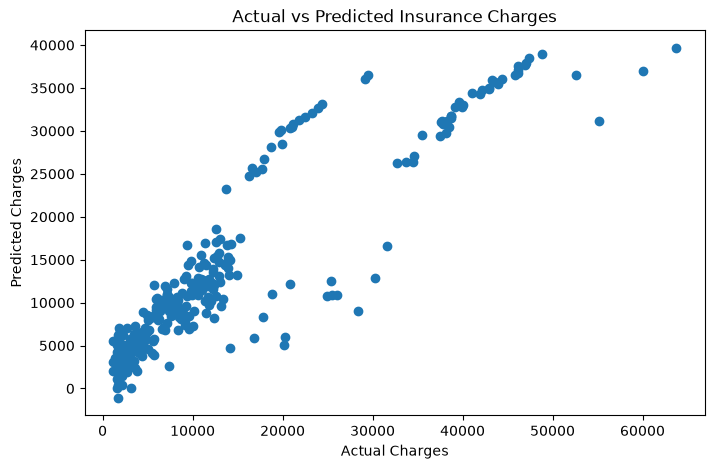

In [58]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")

plt.title("Actual vs Predicted Insurance Charges")

plt.show()

In [59]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})

comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).abs()

print(comparison.head(10))

print("\nAverage Error:", comparison["Error"].mean())
print("Maximum Error:", comparison["Error"].max())

        Actual     Predicted        Error
0   8688.85885   8143.693884   545.164966
1   5708.86700   5737.115683    28.248683
2  11436.73815  14369.314876  2932.576726
3  38746.35510  31745.513636  7000.841464
4   4463.20510   8962.386657  4499.181557
5   9304.70190  13149.722353  3845.020453
6  38511.62830  30446.760679  8064.867621
7   2150.46900   1453.288813   697.180187
8   7345.72660  10633.018402  3287.291802
9  10264.44210  11318.943794  1054.501694

Average Error: 4177.045561036324
Maximum Error: 24111.22112111981


In [60]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

dt_model = Pipeline(steps=[("preprocessor", create_preprocessor()),("regressor", DecisionTreeRegressor(random_state=42))])

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [61]:
dt_pred = dt_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("---------------------")
print("MAE:", round(dt_mae, 2))
print("RMSE:", round(dt_rmse, 2))
print("R2 Score:", round(dt_r2, 4))

Decision Tree Results
---------------------
MAE: 2787.72
RMSE: 5904.67
R2 Score: 0.8103


In [62]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[("preprocessor", create_preprocessor()), ("regressor", RandomForestRegressor(n_estimators=100, random_state=42))])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [63]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Results
---------------------
MAE: 2657.61
RMSE: 4724.02
R2 Score: 0.8786


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# RANDOM FOREST HYPERPARAMETER TUNING
# Parameters to test
param_distributions = {
    "regressor__n_estimators": [200, 300, 400, 500, 600],
    "regressor__max_depth": [None, 5, 8, 10, 12, 15, 20],
    "regressor__min_samples_split": [2, 5, 10, 15],
    "regressor__min_samples_leaf": [1, 2, 4, 6],
    "regressor__max_features": [1.0, "sqrt", 0.8]
}

# Create randomized search
random_search = RandomizedSearchCV(estimator=rf_model, param_distributions=param_distributions, n_iter=30, cv=5, scoring="neg_mean_absolute_error", random_state=42, n_jobs=-1, verbose=1)

# Train and tune using training data only
random_search.fit(X_train, y_train)

# Get the best model
best_rf_model = random_search.best_estimator_

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-random_search.best_score_, 2))


# EVALUATE TUNED MODEL
best_rf_pred = best_rf_model.predict(X_test)

best_mae = mean_absolute_error(y_test, best_rf_pred)
best_mse = mean_squared_error(y_test, best_rf_pred)
best_rmse = np.sqrt(best_mse)
best_r2 = r2_score(y_test, best_rf_pred)

print("\nTuned Random Forest Results")
print("---------------------------")
print("MAE:", round(best_mae, 2))
print("RMSE:", round(best_rmse, 2))
print("R2 Score:", round(best_r2, 4))


# COMPARE ORIGINAL AND TUNED MODELS

comparison_results = pd.DataFrame({"Metric": ["MAE", "RMSE", "R2 Score"], "Original Random Forest": [rf_mae, rf_rmse, rf_r2], "Tuned Random Forest": [best_mae, best_rmse, best_r2]})

print("\nModel Comparison")
print("----------------")
print(comparison_results)


Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
import joblib
from pathlib import Path

# Create the models directory if it doesn't exist
Path("../models").mkdir(parents=True, exist_ok=True)

# Save the tuned Random Forest model
joblib.dump(best_rf_model, "../models/random_forest_model.pkl")

print("Tuned Random Forest model saved successfully!")